# Fluorescence collection Monte Carlo

One parameter list (`components`) drives both the `raytracing` package (display + slow reference Monte Carlo) and the fast vectorized Monte Carlo.
Both trace the *same* `ImagingPath` element list, so they cannot diverge.

Conventions
- Lab coordinate `z` = distance along the optical axis from the **nominal** cloud position (mm).
- Cloud displacement `dz` is positive toward L1; `y0` is vertical displacement.
- Emission is isotropic in 3D. Each ray is traced in x and y separately with the same ray-transfer (ABCD) matrices, and every aperture is circular: a ray survives if x^2 + y^2 <= R^2 at that element.
- Efficiency is reported as percent of 4 pi.
- Speed-up used by both methods: rays are only drawn inside the cone that can pass the first aperture (exact, not an approximation); the result is weighted by that cone's solid angle.
- Only paraxial ideal lenses (`Lens(f, diameter)`): no aberrations.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from raytracing import ImagingPath, Space, Lens, Aperture, Ray

%matplotlib widget
plt.rc('axes', grid=True)
plt.rc('font', family='serif')
plt.rc('xtick', labelsize=14)
plt.rc('ytick', labelsize=14)
plt.rc('axes', titlesize=16, labelsize=16)
plt.rc('legend', fontsize=14)
plt.rc('figure', titlesize=18)

rng = np.random.default_rng()

## Core functions (shared by everything below)

In [2]:
def active_components(components):
    return sorted([c for c in components if c['on']], key=lambda c: c['z'])


def build_path(components, dz=0.0):
    """ImagingPath for a cloud displaced by dz (mm, + toward L1)."""
    path = ImagingPath()
    path.objectHeight = OBJECT_HEIGHT
    z_prev = dz
    for c in active_components(components):
        gap = c['z'] - z_prev
        if gap < 0:
            raise ValueError(f"cloud at dz={dz} mm is past {c['name']} (z={c['z']} mm)")
        if gap > 0:
            path.append(Space(d=gap))
        if c['kind'] == 'lens':
            path.append(Lens(f=c['f'], diameter=c['D'], label=c['name']))
        elif c['kind'] == 'aperture':
            path.append(Aperture(diameter=c['D'], label=c['name']))
        else:
            raise ValueError(f"unknown kind {c['kind']}")
        z_prev = c['z']
    return path


def path_to_abcd(path):
    """(A, B, C, D, aperture radius) for every element, read straight from the raytracing path."""
    return [(e.A, e.B, e.C, e.D, e.apertureDiameter / 2) for e in path.elements]


def cone_half_angle(path, x0=0.0, y0=0.0):
    """Half-angle of a cone around the axis that contains every ray able to pass the first
    finite aperture: tan(cap) = (R + r0) / d. Rays outside it are blocked, so we never sample them."""
    d = 0.0
    for e in path.elements:
        if np.isfinite(e.apertureDiameter):
            return np.arctan((e.apertureDiameter / 2 + np.hypot(x0, y0)) / d) if d > 0 else np.pi / 2
        d += e.B if e.C == 0 else 0.0     # free space: B is the length
    return np.pi / 2


def sample_slopes(n, cap, rng):
    """Isotropic directions with polar angle <= cap, returned as paraxial slopes dx/dz, dy/dz.
    Uniform cos(polar angle) -> isotropic. Weight of the sample = (1 - cos(cap)) / 2 of 4 pi."""
    cos_t = rng.uniform(np.cos(cap), 1.0, n)
    phi = rng.uniform(0.0, 2 * np.pi, n)
    sin_t = np.sqrt(1.0 - cos_t**2)
    with np.errstate(divide='ignore'):
        return sin_t * np.cos(phi) / cos_t, sin_t * np.sin(phi) / cos_t


def _to_percent(hits, n, cap):
    """Efficiency and 1-sigma error in percent of 4 pi. The error uses (hits+1)/(n+2) so it is
    not zero when hits = 0."""
    w = (1 - np.cos(cap)) / 2
    p, p_err = hits / n, (hits + 1) / (n + 2)
    return 100 * w * p, 100 * w * np.sqrt(p_err * (1 - p_err) / n)


def vector_mc(components, y0=0.0, dz=0.0, n_rays=1_000_000, x0=0.0, rng=rng, chunk=2_000_000):
    """Fast 3D Monte Carlo. Aperture test uses the ray entering each element, same as raytracing."""
    path = build_path(components, dz)
    elems = path_to_abcd(path)
    cap = cone_half_angle(path, x0, y0)
    hits, done = 0, 0
    while done < n_rays:
        m = min(chunk, n_rays - done)
        tx, ty = sample_slopes(m, cap, rng)
        x = np.full(m, float(x0))
        y = np.full(m, float(y0))
        for A, B, C, D, R in elems:
            if np.isfinite(R):
                keep = x * x + y * y <= R * R
                x, y, tx, ty = x[keep], y[keep], tx[keep], ty[keep]
            x, tx = A * x + B * tx, C * x + D * tx
            y, ty = A * y + B * ty, C * y + D * ty
        hits += x.size
        done += m
    return _to_percent(hits, n_rays, cap)


def raytrace_mc(components, y0=0.0, dz=0.0, n_rays=2000, x0=0.0, rng=rng):
    """Slow reference: every ray goes through raytracing's own path.trace(), once for x and once for y.
    raytracing only checks |y| per axis, so the circular test x^2 + y^2 <= R^2 is applied here
    on the rays it returns (trace[k] is the ray entering element k)."""
    path = build_path(components, dz)
    radii = [e.apertureDiameter / 2 for e in path.elements]
    cap = cone_half_angle(path, x0, y0)
    tx, ty = sample_slopes(n_rays, cap, rng)
    hits = 0
    for i in range(n_rays):
        rx = path.trace(Ray(y=x0, theta=tx[i]))
        ry = path.trace(Ray(y=y0, theta=ty[i]))
        ok = True
        for k, R in enumerate(radii):
            if np.isfinite(R) and rx[k].y**2 + ry[k].y**2 > R**2:
                ok = False
                break
        hits += ok
    return _to_percent(hits, n_rays, cap)


def first_aperture_ceiling(components, dz=0.0):
    """On-axis analytic ceiling (percent of 4 pi) from the first finite aperture alone."""
    c = next(c for c in active_components(components) if np.isfinite(c['D']))
    d = c['z'] - dz
    return 100 * (1 - d / np.hypot(d, c['D'] / 2)) / 2


def describe(components):
    lines = []
    for c in active_components(components):
        s = f"{c['name']:<10} z={c['z']:6.1f}  D={c['D']:5.1f}"
        if c['kind'] == 'lens':
            s += f"  f={c['f']:5.1f}"
        lines.append(s)
    return "\n".join(lines)

## Parameters
Edit only this cell. Each component has an absolute position `z` (mm from the nominal cloud), and `on` toggles it.
Components are sorted by `z` (ties keep list order), so turning a lens off just removes it; the spaces are recomputed.
The last aperture is the detector.

In [275]:
setupTitle = "Set up first half 2026 with PMT"
# --- Distances, each measured from the previous element [mm] ---
cloud_to_viewport  = 83.0
viewport_to_L1     = 0.0
L1_to_L2           = 50.0
L2_to_L3           = 0.0
L3_to_PMT_body     = 20.0
PMT_body_to_head   = 16.0     # channel entrance -> photocathode (datasheet)

# --- Absolute positions [mm] ---
z_viewport = cloud_to_viewport
z_L1       = z_viewport + viewport_to_L1
z_L2       = z_L1 + L1_to_L2
z_L3       = z_L2 + L2_to_L3
z_PMT_body = z_L3 + L3_to_PMT_body
z_PMT_head = z_PMT_body + PMT_body_to_head

components = [
    dict(name='view port', kind='aperture', z=z_viewport,           D=30.0,  on=True),
    dict(name='L1',        kind='lens',     z=z_L1,       f=60.0,   D=50.8,  on=True),
    dict(name='L2',        kind='lens',     z=z_L2,       f=25.4,   D=25.4,  on=True),
    dict(name='L3',        kind='lens',     z=z_L3,       f=50.0,   D=25.4,  on=False),
    dict(name='PMT body',  kind='aperture', z=z_PMT_body,           D=7.0,   on=True),   # 7 mm channel
    dict(name='PMT head',  kind='aperture', z=z_PMT_head,           D=5.0,   on=True),   # 5 mm cathode
]

OBJECT_HEIGHT  = 3.0
FAN_Y          = 0.0
FAN_THETA_MAX  = 0.35
N_FAN_RAYS     = 51

In [169]:
setupTitle = "Set up first half 2026, 10mm diode"
# --- Distances, each measured from the previous element [mm] ---
cloud_to_viewport  = 83.0
viewport_to_L1     = 0.0
L1_to_L2           = 50.0
L2_to_L3           = 0.0
L3_to_PMT_body     = 22.0
PMT_body_to_head   = 0.0     # channel entrance -> photocathode (datasheet)

# --- Absolute positions [mm] ---
z_viewport = cloud_to_viewport
z_L1       = z_viewport + viewport_to_L1
z_L2       = z_L1 + L1_to_L2
z_L3       = z_L2 + L2_to_L3
z_PMT_body = z_L3 + L3_to_PMT_body
z_PMT_head = z_PMT_body + PMT_body_to_head

components = [
    dict(name='view port', kind='aperture', z=z_viewport,           D=30.0,  on=True),
    dict(name='L1',        kind='lens',     z=z_L1,       f=60.0,   D=50.8,  on=True),
    dict(name='L2',        kind='lens',     z=z_L2,       f=25.4,   D=25.4,  on=True),
    dict(name='L3',        kind='lens',     z=z_L3,       f=50.0,   D=25.4,  on=False),
    dict(name='PMT body',  kind='aperture', z=z_PMT_body,           D=7.0,   on=0),   # 
    dict(name='PMT head',  kind='aperture', z=z_PMT_head,           D=10.0,   on=1),   # 
]

OBJECT_HEIGHT  = 3.0
FAN_Y          = 0.0
FAN_THETA_MAX  = 0.35
N_FAN_RAYS     = 51

In [49]:
setupTitle = 'f=60mm objective, followed by 31mm fesnel'
# --- Distances, each measured from the previous element [mm] ---
cloud_to_viewport  = 83.0
viewport_to_L1     = 0.0
L1_to_L2           = 20.0     # L2 off, so this is the L1 -> Fresnel spacing
L2_to_L3           = 0.0
L3_to_det_front    = 22.0     # best of a quick scan; flat from 24 to 26, worse past 28
det_front_to_det   = 4.0

# --- Absolute positions [mm] ---
z_viewport  = cloud_to_viewport
z_L1        = z_viewport + viewport_to_L1
z_L2        = z_L1 + L1_to_L2
z_L3        = z_L2 + L2_to_L3
z_det_front = z_L3 + L3_to_det_front
z_det       = z_det_front + det_front_to_det

components = [
    dict(name='view port',      kind='aperture', z=z_viewport,          D=30.0,  on=True),
    dict(name='L1',             kind='lens',     z=z_L1,        f=60.0, D=50.8,  on=True),
    dict(name='L2',             kind='lens',     z=z_L2,        f=50.0, D=25.4,  on=False),
    dict(name='L3 Fresnel',     kind='lens',     z=z_L3,        f=31.0, D=45.7,  on=True),   # D = clear aperture of a 2" Fresnel
    dict(name='detector front', kind='aperture', z=z_det_front,         D=10.0,  on=True),
    dict(name='detector',       kind='aperture', z=z_det,               D=10.0,  on=True),
]

OBJECT_HEIGHT  = 10.0
FAN_Y          = 1.0
FAN_THETA_MAX  = 0.2
N_FAN_RAYS     = 51

In [ ]:
setupTitle = 'f=60mm objective, followed by 31mm fesnel, into pmt'
# --- Distances, each measured from the previous element [mm] ---
cloud_to_viewport  = 83.0
viewport_to_L1     = 0.0
L1_to_L2           = 30.0     # L2 off, so this is the L1 -> Fresnel spacing
L2_to_L3           = 0.0
L3_to_det_front    = 30.0     # best of a quick scan; flat from 24 to 26, worse past 28
det_front_to_det   = 16.0

# --- Absolute positions [mm] ---
z_viewport  = cloud_to_viewport
z_L1        = z_viewport + viewport_to_L1
z_L2        = z_L1 + L1_to_L2
z_L3        = z_L2 + L2_to_L3
z_det_front = z_L3 + L3_to_det_front
z_det       = z_det_front + det_front_to_det

components = [
    dict(name='view port',      kind='aperture', z=z_viewport,          D=30.0,  on=True),
    dict(name='L1',             kind='lens',     z=z_L1,        f=60.0, D=50.8,  on=True),
    dict(name='L2',             kind='lens',     z=z_L2,        f=50.0, D=25.4,  on=False),
    dict(name='L3 Fresnel',     kind='lens',     z=z_L3,        f=31.0, D=45.7,  on=True),   # D = clear aperture of a 2" Fresnel
    dict(name='detector front', kind='aperture', z=z_det_front,         D=7.0,  on=True),
    dict(name='detector',       kind='aperture', z=z_det,               D=5.0,  on=True),
]

OBJECT_HEIGHT  = 10.0
FAN_Y          = 0.0
FAN_THETA_MAX  = 0.2
N_FAN_RAYS     = 51

In [276]:
setupTitle = 'f=60mm objective, followed by 31mm fesnel, d lens, into pmt'
# --- Distances, each measured from the previous element [mm] ---
cloud_to_viewport  = 83.0
viewport_to_L1     = 0.0
L1_to_L2           = 30.0     # L2 off, so this is the L1 -> Fresnel spacing
L2_to_L3           = 35.0
L3_to_det_front    = 50.0     # best of a quick scan; flat from 24 to 26, worse past 28
det_front_to_det   = 16.0

# --- Absolute positions [mm] ---
z_viewport  = cloud_to_viewport
z_L1        = z_viewport + viewport_to_L1
z_L2        = z_L1 + L1_to_L2
z_L3        = z_L2 + L2_to_L3
z_det_front = z_L3 + L3_to_det_front
z_det       = z_det_front + det_front_to_det

components = [
    dict(name='view port',      kind='aperture', z=z_viewport,          D=30.0,  on=True),
    dict(name='L1',             kind='lens',     z=z_L1,        f=60.0, D=50.8,  on=True),
    dict(name='L2',             kind='lens',     z=z_L2,        f=31.0, D=45.4,  on=True),
    dict(name='L3 Fresnel',     kind='lens',     z=z_L3,        f=10.0, D=45.7,  on=True),   # D = clear aperture of a 2" Fresnel
    dict(name='detector front', kind='aperture', z=z_det_front,         D=7.0,  on=True),
    dict(name='detector',       kind='aperture', z=z_det,               D=5.0,  on=True),
]

OBJECT_HEIGHT  = 10.0
FAN_Y          = 0.0
FAN_THETA_MAX  = 0.2
N_FAN_RAYS     = 51

## Ray-trace display

| -0.326    2.184 |
|                 |
| -0.038   -2.813 |
f=26.197
setup name =
f=60mm objective, followed by 31mm fesnel
On-axis ceiling from first aperture: 0.797 % of 4 pi


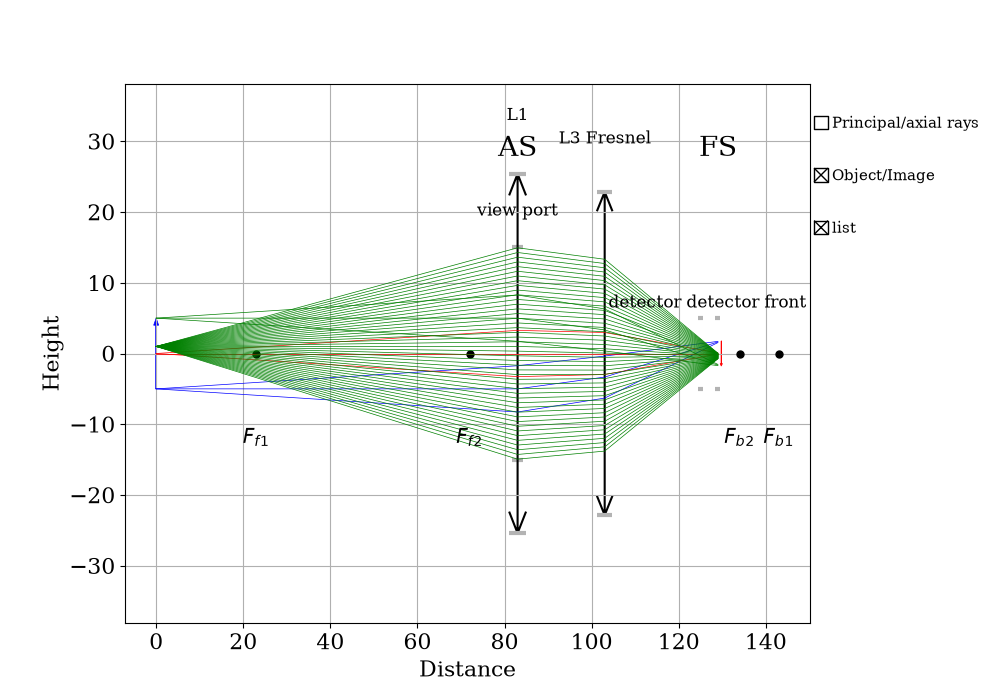

In [50]:
path = build_path(components)
print(path)
print('setup name =')
print(setupTitle)
print(f"On-axis ceiling from first aperture: {first_aperture_ceiling(components):.3f} % of 4 pi")
fan = [Ray(y=FAN_Y, theta=t) for t in np.linspace(-FAN_THETA_MAX, FAN_THETA_MAX, N_FAN_RAYS)]
path.display(raysList=[fan])

## Plot line scans: efficiency vs z (fixed y) and vs y (fixed z)
Error bars are 1-sigma binomial counting errors. The two methods should agree within them.

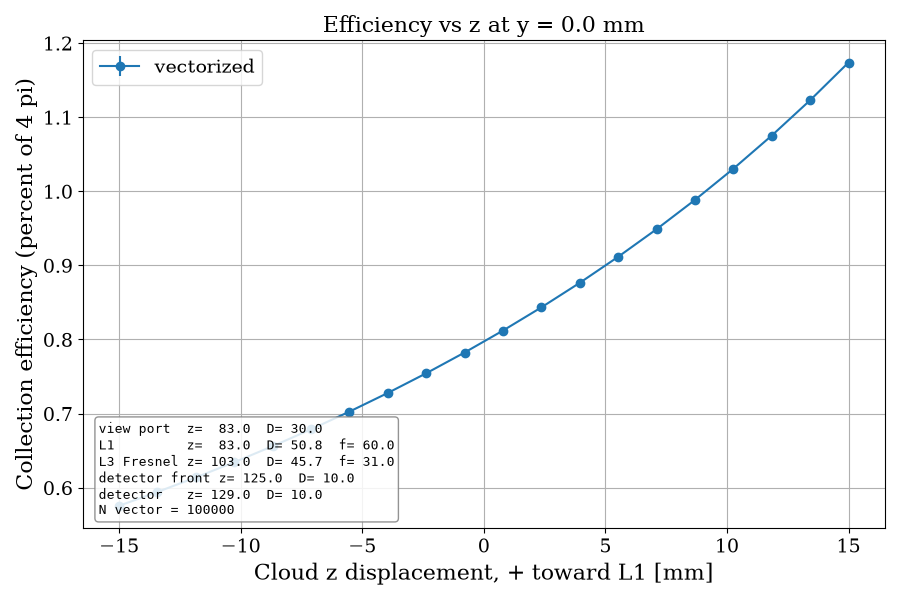

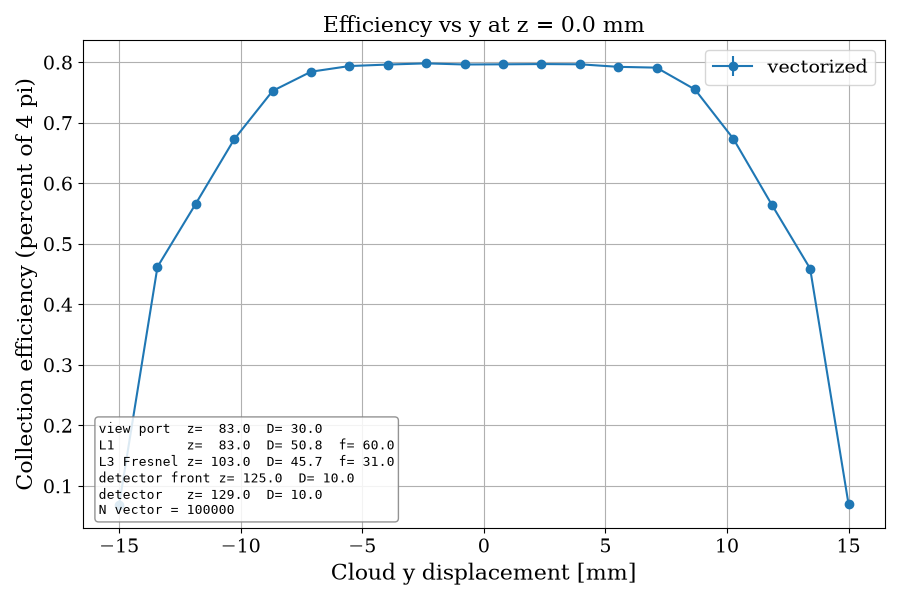

In [51]:
# --- Line scan settings ---
RUN_RAYTRACE = False        # True = also run the slow raytracing Monte Carlo and compare
n_vector     = 1_000_00    # rays per point, vectorized
n_raytrace   = 5_000        # rays per point, raytracing (only used if RUN_RAYTRACE)
y_fix  = 0.0                # mm, for the z scan
z_fix  = 0.0                # mm, for the y scan
z_scan = np.linspace(-15, 15, 20)
y_scan = np.linspace(-15, 15, 20)

def scan(fn, n, ys, zs):
    out = np.array([fn(components, y0=y, dz=z, n_rays=n) for y, z in zip(ys, zs)])
    return out[:, 0], out[:, 1]

v_z, ve_z = scan(vector_mc, n_vector, np.full_like(z_scan, y_fix), z_scan)
v_y, ve_y = scan(vector_mc, n_vector, y_scan, np.full_like(y_scan, z_fix))
if RUN_RAYTRACE:
    r_z, re_z = scan(raytrace_mc, n_raytrace, np.full_like(z_scan, y_fix), z_scan)
    r_y, re_y = scan(raytrace_mc, n_raytrace, y_scan, np.full_like(y_scan, z_fix))

info = describe(components) + f"\nN vector = {n_vector}"
if RUN_RAYTRACE:
    info += f"\nN raytrace = {n_raytrace}"

def info_box():
    plt.gca().text(0.02, 0.02, info, transform=plt.gca().transAxes, va='bottom', family='monospace', fontsize=9,
                   bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='gray'))

plt.figure(figsize=(9, 6))
plt.errorbar(z_scan, v_z, ve_z, fmt='o-', label='vectorized')
if RUN_RAYTRACE:
    plt.errorbar(z_scan, r_z, re_z, fmt='s--', capsize=3, label='raytracing')
plt.xlabel('Cloud z displacement, + toward L1 [mm]')
plt.ylabel('Collection efficiency (percent of 4 pi)')
plt.title(f'Efficiency vs z at y = {y_fix} mm')
plt.legend()
info_box()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
plt.errorbar(y_scan, v_y, ve_y, fmt='o-', label='vectorized')
if RUN_RAYTRACE:
    plt.errorbar(y_scan, r_y, re_y, fmt='s--', capsize=3, label='raytracing')
plt.xlabel('Cloud y displacement [mm]')
plt.ylabel('Collection efficiency (percent of 4 pi)')
plt.title(f'Efficiency vs y at z = {z_fix} mm')
plt.legend()
info_box()
plt.tight_layout()
plt.show()

if RUN_RAYTRACE:
    pull = np.concatenate([(v_z - r_z) / np.hypot(ve_z, re_z), (v_y - r_y) / np.hypot(ve_y, re_y)])
    print(f"Difference in units of combined sigma: rms = {np.sqrt(np.mean(pull**2)):.2f}  (expect about 1)")

## Plot heat maps
The ray-tracing heat map is slow (about `len(z_hm) * len(y_hm) * n_raytrace` traces). Keep its grid coarse.

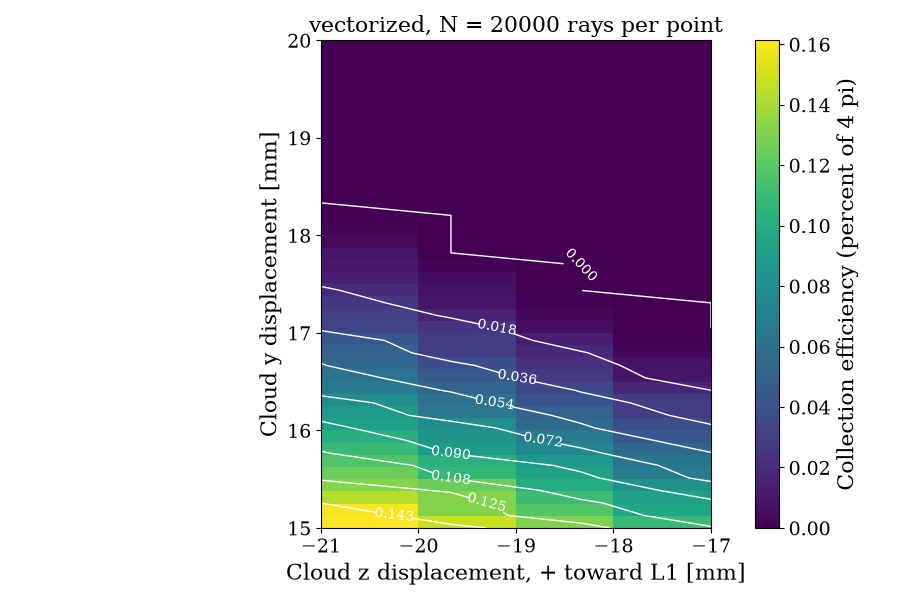

peak = 0.161 %, on-axis ceiling from first aperture = 0.797 %


In [15]:
# --- Heat map settings ---
RUN_RAYTRACE = False        # True = also run the slow raytracing Monte Carlo and compare
n_vector     = 200_00      # rays per point, vectorized
n_raytrace   = 2_000        # rays per point, raytracing (only used if RUN_RAYTRACE)
z_hm = np.linspace(-21,-17 , 4)
y_hm = np.linspace(15, 20, 40)
contour_fracs = np.linspace(0, 1, 10)     # contour levels as fractions of the peak

def heatmap(fn, n):
    eff = np.zeros((len(z_hm), len(y_hm)))
    err = np.zeros_like(eff)
    for i, z in enumerate(z_hm):
        for j, y in enumerate(y_hm):
            eff[i, j], err[i, j] = fn(components, y0=y, dz=z, n_rays=n)
    return eff, err

maps = []
hm_v, hme_v = heatmap(vector_mc, n_vector)
maps.append((hm_v, 'vectorized', n_vector))
if RUN_RAYTRACE:
    hm_r, hme_r = heatmap(raytrace_mc, n_raytrace)
    maps.append((hm_r, 'raytracing', n_raytrace))

vmax = max(m[0].max() for m in maps)
extent = [z_hm[0], z_hm[-1], y_hm[0], y_hm[-1]]
Z, Y = np.meshgrid(z_hm, y_hm)

for eff, name, n in maps:
    plt.figure(figsize=(9, 6))
    plt.imshow(eff.T, extent=extent, origin='lower', aspect='equal', cmap='viridis', vmin=0, vmax=vmax)
    plt.colorbar(label='Collection efficiency (percent of 4 pi)')
    cs = plt.contour(Z, Y, eff.T, levels=vmax * np.array(contour_fracs), colors='white', linewidths=1.0)
    plt.clabel(cs, fmt='%.3f', fontsize=10)
    plt.grid(False)
    plt.xlabel('Cloud z displacement, + toward L1 [mm]')
    plt.ylabel('Cloud y displacement [mm]')
    plt.title(f'{name}, N = {n} rays per point')
    plt.tight_layout()
    plt.show()

if RUN_RAYTRACE:
    pull_hm = (hm_v - hm_r) / np.hypot(hme_v, hme_r)
    plt.figure(figsize=(9, 6))
    plt.imshow(pull_hm.T, extent=extent, origin='lower', aspect='equal', cmap='RdBu_r', vmin=-4, vmax=4)
    plt.colorbar(label='(vector - raytrace) / combined sigma')
    plt.grid(False)
    plt.xlabel('Cloud z displacement, + toward L1 [mm]')
    plt.ylabel('Cloud y displacement [mm]')
    plt.title('Difference in units of sigma')
    plt.tight_layout()
    plt.show()
    print(f"rms pull = {np.sqrt(np.mean(pull_hm**2)):.2f}  (expect about 1)")

print(f"peak = {hm_v.max():.3f} %, on-axis ceiling from first aperture = {first_aperture_ceiling(components):.3f} %")